# Malayalam Named Entity Recognition — 03. Evaluation & Model Comparison
Evaluates the two final fine-tuned checkpoints on the **Naamapadam Malayalam test set** (965 valid sentences):
- entity-level precision / recall / F1 (`seqeval`, strict span matching)
- token-level accuracy and confusion matrices
- invalid IOB2 transitions (an `I-X` not preceded by `B-X`/`I-X`)
- error analysis: where the CRF fixes the linear head's mistakes

## 0. Environment Setup
Works both **locally** (run from the project's `submission codes/` folder, which sits next to `dataset/` and `results/`) and on **Google Colab** (Runtime → Change runtime type → GPU).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install "datasets<4" seqeval pytorch-crf seaborn

# Project root = folder that contains dataset/ and results/
PROJECT_DIR = os.path.abspath("..") if os.path.isdir(os.path.join("..", "dataset")) else os.path.abspath(".")
print("Running in Colab:", IN_COLAB)
print("Project directory:", PROJECT_DIR)

Running in Colab: False
Project directory: E:\Downloads\SEM 7\NLP\Project


In [2]:
import torch
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import disable_progress_bars, logging as hub_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error(); disable_progress_bars()

# ---------------- Paths ----------------
DATA_DIR = os.path.join(PROJECT_DIR, "dataset")
TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
VAL_CSV = os.path.join(DATA_DIR, "validation.csv")
TEST_CSV = os.path.join(DATA_DIR, "test.csv")
MODEL_SAVE_DIR = os.path.join(PROJECT_DIR, "results", "malayalam_ner_model")          # IndicBERTv2 + Linear head
CRF_MODEL_SAVE_DIR = os.path.join(PROJECT_DIR, "results", "malayalam_ner_crf_model")  # IndicBERTv2 + CRF head

# ---------------- Hardware ----------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = torch.cuda.is_available()

# ---------------- Model & labels (IOB2) ----------------
MODEL_NAME = "ai4bharat/IndicBERTv2-MLM-only"
ID2LABEL = {0: "O", 1: "B-PER", 2: "I-PER", 3: "B-ORG", 4: "I-ORG", 5: "B-LOC", 6: "I-LOC"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}
NUM_LABELS = len(ID2LABEL)
ENTITY_COLORS = {"PER": "#3B82F6", "ORG": "#10B981", "LOC": "#F59E0B",
                 "MISC": "#8B5CF6", "DATE": "#EC4899", "CARDINAL": "#06B6D4"}

# ---------------- Hyperparameters (used for the final models) ----------------
MAX_LENGTH = 128
BATCH_SIZE = 32 if torch.cuda.is_available() else 8
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 0.01
EPOCHS = 3
SEED = 42
MAX_TRAIN_SAMPLES = 50000

print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("torch", torch.__version__)

Device: cuda | NVIDIA GeForce RTX 3050 6GB Laptop GPU
torch 2.6.0+cu124


**Dataset.** If `dataset/*.csv` is not present (e.g. on Colab), the Malayalam split of [Naamapadam](https://huggingface.co/datasets/ai4bharat/naamapadam) is downloaded from HuggingFace and exported to the same CSV format.

In [3]:
def ensure_dataset():
    if all(os.path.exists(p) for p in (TRAIN_CSV, VAL_CSV, TEST_CSV)):
        print("Dataset found in", DATA_DIR)
        return
    from datasets import load_dataset
    ds = load_dataset("ai4bharat/naamapadam", "ml", trust_remote_code=True)
    os.makedirs(DATA_DIR, exist_ok=True)
    for split, path in [("train", TRAIN_CSV), ("validation", VAL_CSV), ("test", TEST_CSV)]:
        df = ds[split].to_pandas()[["tokens", "ner_tags"]]
        df["tokens"] = df["tokens"].map(lambda x: str(list(x)))
        df["ner_tags"] = df["ner_tags"].map(lambda x: str([int(t) for t in x]))
        df.to_csv(path, index=False)
    print("Dataset downloaded and saved to", DATA_DIR)

ensure_dataset()

Dataset found in E:\Downloads\SEM 7\NLP\Project\dataset


**Checkpoints.** The fine-tuned weights (~1.1 GB each) are too large to submit. Locally they are read from `results/malayalam_ner_model` and `results/malayalam_ner_crf_model`. On Colab, upload them to Google Drive and point `MODEL_SAVE_DIR` / `CRF_MODEL_SAVE_DIR` at them, or train them with `02_Model_Training.ipynb` (`DEMO_MODE = False`).

In [4]:
import ast
import pandas as pd
from torch.utils.data import Dataset


def load_ner_dataframe(csv_path, max_samples=None):
    """Loads CSV containing string representation of tokens and ner_tags."""
    df = pd.read_csv(csv_path)
    if max_samples and max_samples < len(df):
        df = df.iloc[:max_samples].copy()

    processed_records = []
    for idx, row in df.iterrows():
        try:
            tokens = ast.literal_eval(row['tokens']) if isinstance(row['tokens'], str) else row['tokens']
            tags = ast.literal_eval(row['ner_tags']) if isinstance(row['ner_tags'], str) else row['ner_tags']
            if len(tokens) == len(tags) and len(tokens) > 0:
                processed_records.append({"tokens": tokens, "ner_tags": tags})
        except Exception:
            continue

    return processed_records


class MalayalamNERDataset(Dataset):
    """PyTorch Dataset with HuggingFace Fast Tokenizer Subword Alignment."""

    def __init__(self, records, tokenizer, max_length=MAX_LENGTH):
        self.records = records
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]
        word_list = record['tokens']
        label_list = record['ner_tags']

        encoding = self.tokenizer(
            word_list,
            is_split_into_words=True,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        word_ids = encoding.word_ids(batch_index=0)
        aligned_labels = []
        previous_word_idx = None

        for word_idx in word_ids:
            if word_idx is None:
                # Special tokens ([CLS], [SEP], [PAD]) get -100 label
                aligned_labels.append(-100)
            elif word_idx != previous_word_idx:
                # First subword token of the word gets original label
                aligned_labels.append(label_list[word_idx])
            else:
                # Subsequent subword tokens get -100 so loss ignored
                aligned_labels.append(-100)
            previous_word_idx = word_idx

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(aligned_labels, dtype=torch.long)
        }

In [5]:
import torch.nn as nn
from transformers import AutoModelForTokenClassification, AutoConfig, AutoModel, AutoTokenizer
from torchcrf import CRF


class MalayalamBERTCRF(nn.Module):
    """Transformer sequence encoder topped with a Conditional Random Field (CRF) layer."""
    def __init__(self, model_name=MODEL_NAME, num_labels=NUM_LABELS):
        super().__init__()
        self.num_labels = num_labels
        self.config = AutoConfig.from_pretrained(model_name)
        self.bert = AutoModel.from_pretrained(model_name, config=self.config)
        self.dropout = nn.Dropout(self.config.hidden_dropout_prob)
        self.classifier = nn.Linear(self.config.hidden_size, num_labels)
        self.crf = CRF(num_labels, batch_first=True)

    def forward(self, input_ids, attention_mask, labels=None):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        sequence_output = self.dropout(outputs[0])
        emissions = self.classifier(sequence_output)

        if labels is not None:
            # Valid positions = first subword of every word; [CLS] forced True for pytorch-crf
            mask = (labels != -100)
            mask[:, 0] = True
            clean_labels = labels.clone()
            clean_labels[clean_labels == -100] = 0
            loss = -self.crf(emissions, clean_labels, mask=mask, reduction='mean')
            return type('CRFOutput', (object,), {"loss": loss, "logits": emissions})()
        else:
            mask = (attention_mask == 1)
            preds = self.crf.decode(emissions, mask=mask)
            return type('CRFOutput', (object,), {"logits": emissions, "predictions": preds})()

    def save_pretrained(self, save_dir):
        os.makedirs(save_dir, exist_ok=True)
        torch.save(self.state_dict(), os.path.join(save_dir, "pytorch_model.bin"))
        self.config.save_pretrained(save_dir)

    def load_pretrained(self, save_dir):
        self.load_state_dict(torch.load(os.path.join(save_dir, "pytorch_model.bin"), map_location=DEVICE))


def build_ner_model(model_name=MODEL_NAME, num_labels=NUM_LABELS, use_crf=True):
    """Initializes standard Transformer token classifier or CRF-augmented model."""
    if use_crf:
        print("Configuring Model: IndicBERTv2 + Conditional Random Field (CRF) Head")
        return MalayalamBERTCRF(model_name=model_name, num_labels=num_labels)
    print("Configuring Model: IndicBERTv2 + Linear Token Classification Head")
    model_config = AutoConfig.from_pretrained(model_name, num_labels=num_labels,
                                              id2label=ID2LABEL, label2id=LABEL2ID)
    return AutoModelForTokenClassification.from_pretrained(model_name, config=model_config)

## 1. Load Test Set and Final Checkpoints

In [6]:
import time
from torch.utils.data import DataLoader
from seqeval.metrics import classification_report
from sklearn.metrics import confusion_matrix

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
test_records = load_ner_dataframe(TEST_CSV)
test_loader = DataLoader(MalayalamNERDataset(test_records, tokenizer), batch_size=32)
print(f"Test sentences: {len(test_records)}")


def run(model, use_crf):
    model.to(DEVICE).eval()
    L, P = [], []
    t0 = time.time()
    with torch.no_grad():
        for b in test_loader:
            ii, am, lab = b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE), b["labels"].numpy()
            if use_crf:
                preds = model(input_ids=ii, attention_mask=am).predictions
            else:
                preds = model(input_ids=ii, attention_mask=am).logits.argmax(-1).cpu().tolist()
            for i in range(len(lab)):
                sl, sp = [], []
                for j in range(len(lab[i])):
                    if lab[i][j] != -100 and j < len(preds[i]):
                        sl.append(ID2LABEL[int(lab[i][j])]); sp.append(ID2LABEL[int(preds[i][j])])
                L.append(sl); P.append(sp)
    return L, P, time.time() - t0

Test sentences: 965


In [7]:
import gc
linear = AutoModelForTokenClassification.from_pretrained(MODEL_SAVE_DIR)
gold, pred_linear, t_linear = run(linear, use_crf=False)
del linear; gc.collect(); torch.cuda.empty_cache()

crf = MalayalamBERTCRF(model_name=MODEL_NAME)
crf.load_pretrained(CRF_MODEL_SAVE_DIR)
gold_crf, pred_crf, t_crf = run(crf, use_crf=True)
del crf; gc.collect(); torch.cuda.empty_cache()
assert gold == gold_crf
print(f"Inference time on test set — Linear: {t_linear:.1f}s | CRF: {t_crf:.1f}s")

Inference time on test set — Linear: 5.8s | CRF: 6.2s


## 2. Entity-level Classification Reports (seqeval)

In [8]:
print("IndicBERTv2 + Linear head\n" + "=" * 60)
print(classification_report(gold, pred_linear, digits=4))
print("IndicBERTv2 + CRF head\n" + "=" * 60)
print(classification_report(gold, pred_crf, digits=4))

IndicBERTv2 + Linear head
              precision    recall  f1-score   support

         LOC     0.6852    0.7946    0.7358       482
         ORG     0.3763    0.5955    0.4612       309
         PER     0.7899    0.9160    0.8482       714

   micro avg     0.6509    0.8113    0.7223      1505
   macro avg     0.6171    0.7687    0.6817      1505
weighted avg     0.6714    0.8113    0.7328      1505

IndicBERTv2 + CRF head
              precision    recall  f1-score   support

         LOC     0.8660    0.8444    0.8550       482
         ORG     0.6961    0.6375    0.6655       309
         PER     0.8872    0.9258    0.9061       714

   micro avg     0.8445    0.8405    0.8425      1505
   macro avg     0.8164    0.8026    0.8089      1505
weighted avg     0.8412    0.8405    0.8404      1505



## 3. Side-by-side Comparison

In [9]:
def invalid_transitions(P):
    bad = 0
    for s in P:
        prev = "O"
        for t in s:
            if t.startswith("I-") and prev[2:] != t[2:]:
                bad += 1
            prev = t
    return bad

def token_acc(L, P):
    fl, fp = sum(L, []), sum(P, [])
    return sum(a == b for a, b in zip(fl, fp)) / len(fl)

rows = []
for name, P, t in [("Linear", pred_linear, t_linear), ("CRF", pred_crf, t_crf)]:
    d = classification_report(gold, P, output_dict=True)
    rows.append({"Model": f"IndicBERTv2 + {name}",
                 "Precision": d["micro avg"]["precision"], "Recall": d["micro avg"]["recall"], "Micro F1": d["micro avg"]["f1-score"],
                 "Macro F1": d["macro avg"]["f1-score"], "PER F1": d["PER"]["f1-score"], "ORG F1": d["ORG"]["f1-score"],
                 "LOC F1": d["LOC"]["f1-score"], "Token Acc.": token_acc(gold, P),
                 "Invalid IOB2": invalid_transitions(P), "Time (s)": t})
comparison = pd.DataFrame(rows).set_index("Model")
comparison.round(4)

,Precision,Recall,Micro F1,Macro F1,PER F1,ORG F1,LOC F1,Token Acc.,Invalid IOB2,Time (s)
Model,,,,,,,,,,
IndicBERTv2 + Linear,0.6509,0.8113,0.7223,0.6817,0.8482,0.4612,0.7358,0.8869,98,5.7603
IndicBERTv2 + CRF,0.8445,0.8405,0.8425,0.8089,0.9061,0.6655,0.8550,0.9408,20,6.2473


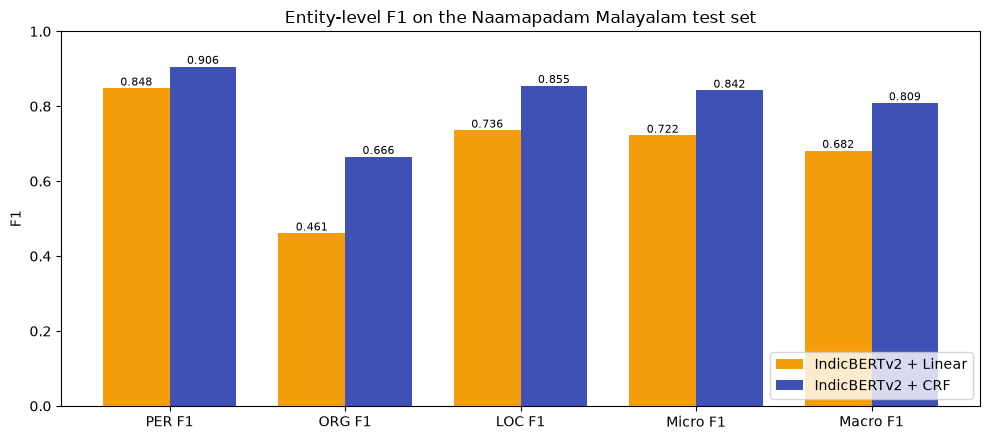

In [10]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 4.5))
cols = ["PER F1", "ORG F1", "LOC F1", "Micro F1", "Macro F1"]
x = np.arange(len(cols))
for k, (name, c) in enumerate([("IndicBERTv2 + Linear", "#F59E0B"), ("IndicBERTv2 + CRF", "#3f51b5")]):
    vals = comparison.loc[name, cols].values.astype(float)
    bars = ax.bar(x + (k - .5) * .38, vals, .38, label=name, color=c)
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(cols); ax.set_ylim(0, 1); ax.set_ylabel("F1")
ax.set_title("Entity-level F1 on the Naamapadam Malayalam test set"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 4. Token-level Confusion Matrices

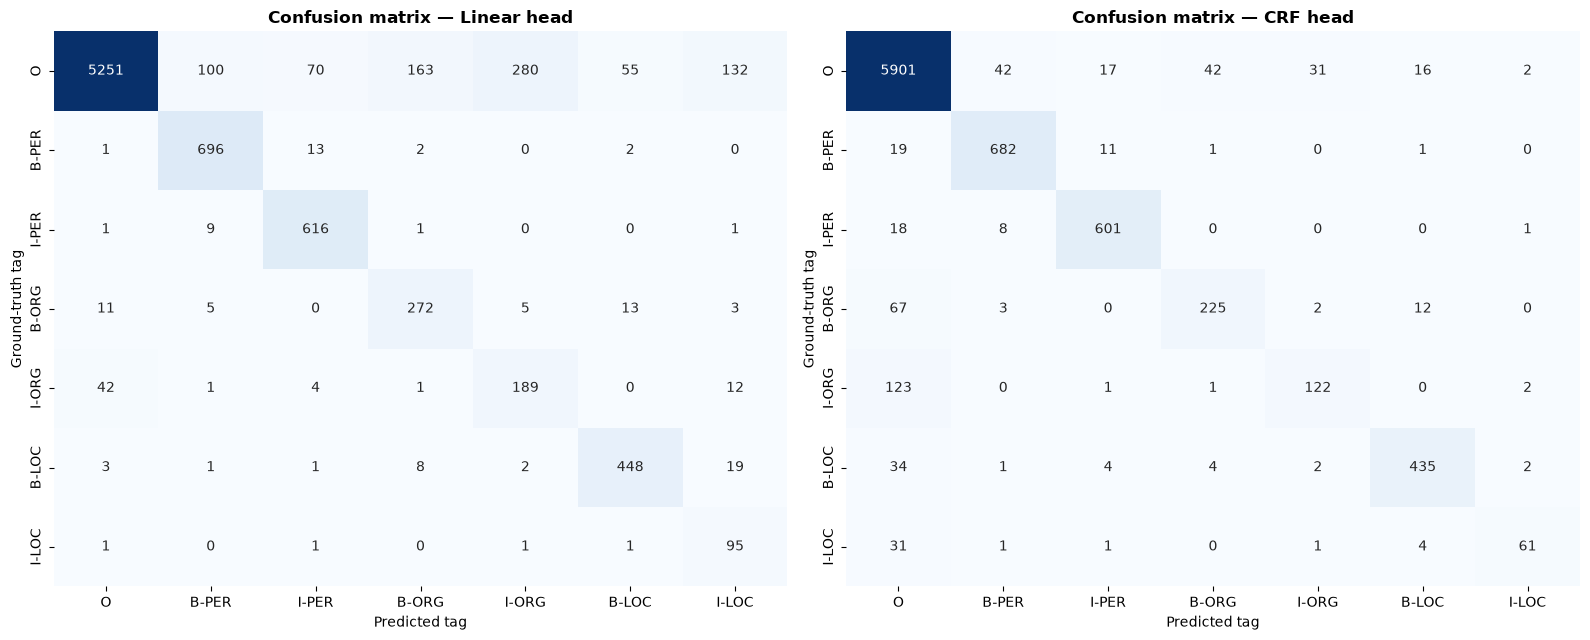

In [11]:
import seaborn as sns
tags_order = [ID2LABEL[i] for i in range(NUM_LABELS)]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (name, P) in zip(axes, [("Linear head", pred_linear), ("CRF head", pred_crf)]):
    cm = confusion_matrix(sum(gold, []), sum(P, []), labels=tags_order)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=tags_order, yticklabels=tags_order, ax=ax, cbar=False)
    ax.set_title(f"Confusion matrix — {name}", fontweight="bold")
    ax.set_xlabel("Predicted tag"); ax.set_ylabel("Ground-truth tag")
plt.tight_layout(); plt.show()

## 5. Error Analysis
Sentences where the two heads disagree, showing tags as `word/TAG` (only non-`O` tags are shown).

In [12]:
def fmt(words, tags):
    return " ".join(f"{w}/{t}" if t != "O" else w for w, t in zip(words, tags))

diff = [i for i in range(len(gold)) if pred_linear[i] != pred_crf[i]]
crf_fixes = [i for i in diff if pred_crf[i] == gold[i]]
print(f"Sentences where heads disagree: {len(diff)} | CRF exactly correct while Linear wrong: {len(crf_fixes)}\n")
for i in crf_fixes[:4]:
    w = test_records[i]["tokens"][:len(gold[i])]
    print("GOLD  :", fmt(w, gold[i])); print("LINEAR:", fmt(w, pred_linear[i])); print("CRF   :", fmt(w, pred_crf[i])); print()

Sentences where heads disagree: 382 | CRF exactly correct while Linear wrong: 191

GOLD  : കോൺഗ്രസ്/B-ORG സംസ്ഥാന അധ്യക്ഷൻ ജി/B-PER പരമേശ്വര/I-PER ഉപമുഖ്യമന്ത്രിയാകും .
LINEAR: കോൺഗ്രസ്/B-ORG സംസ്ഥാന/I-ORG അധ്യക്ഷൻ ജി/B-PER പരമേശ്വര/I-PER ഉപമുഖ്യമന്ത്രിയാകും/B-ORG .
CRF   : കോൺഗ്രസ്/B-ORG സംസ്ഥാന അധ്യക്ഷൻ ജി/B-PER പരമേശ്വര/I-PER ഉപമുഖ്യമന്ത്രിയാകും .

GOLD  : ഇന്ത്യക്ക്/B-LOC ഒപ്പം ആതിഥേയരായ .
LINEAR: ഇന്ത്യക്ക്/B-LOC ഒപ്പം ആതിഥേയരായ/B-LOC .
CRF   : ഇന്ത്യക്ക്/B-LOC ഒപ്പം ആതിഥേയരായ .

GOLD  : ബിജെപി/B-ORG സർക്കാരിന് .
LINEAR: ബിജെപി/B-ORG സർക്കാരിന്/I-ORG .
CRF   : ബിജെപി/B-ORG സർക്കാരിന് .

GOLD  : അക്ഷയ്/B-PER കുമാറിൻറെ/I-PER കേപ്/B-ORG ഓഫ്/I-ORG ഗുഡ്/I-ORG ഫിലിംസ്/I-ORG , ഷബീന/B-PER ഖാൻ/I-PER , തുഷാർ/B-PER കപൂർ/I-PER , ഫോക്സ്/B-ORG സ്റ്റാർ/I-ORG സ്റ്റുഡിയോസ്/I-ORG എന്നിവർ ചേർന്നാണ് നിർമ്മാണം .
LINEAR: അക്ഷയ്/B-PER കുമാറിൻറെ/I-PER കേപ്/B-ORG ഓഫ്/I-ORG ഗുഡ്/I-ORG ഫിലിംസ്/I-ORG ,/I-ORG ഷബീന/B-PER ഖാൻ/I-PER ,/I-ORG തുഷാർ/B-PER കപൂർ/I-PER ,/I-ORG ഫോക്സ്/B-ORG സ്റ്റാർ/I-ORG സ്റ്റുഡിയോസ്/I

In [13]:
# Most frequent invalid transitions produced by the linear head (the CRF transition matrix suppresses these)
from collections import Counter
c = Counter()
for s in pred_linear:
    prev = "O"
    for t in s:
        if t.startswith("I-") and prev[2:] != t[2:]:
            c[f"{prev} -> {t}"] += 1
        prev = t
pd.DataFrame(c.most_common(8), columns=["invalid transition (Linear)", "count"])

,invalid transition (Linear),count
0,O -> I-LOC,21
1,O -> I-ORG,19
2,B-LOC -> I-ORG,15
3,B-ORG -> I-LOC,11
4,O -> I-PER,6
5,I-PER -> I-ORG,5
6,I-ORG -> I-PER,5
7,I-PER -> I-LOC,3


## Summary
- The **CRF head** clearly outperforms the linear head: micro-F1 rises from ≈0.72 to ≈0.84, with the largest gain on **ORG**.
- The linear head's class weighting gives high recall but low precision; the CRF balances the two and produces far fewer invalid IOB2 sequences.
- The CRF checkpoint is therefore used for the demo in `04_Inference_Demo.ipynb`.